# 23. Molecular simulation: pressure and diffusion in a Lennard-Jones liquid

**Track:** advanced example &nbsp;·&nbsp; **Uses:** Chapters 4 and 17

**Reading:** Allen & Tildesley, *Computer Simulation of Liquids* · Frenkel &
Smit, *Understanding Molecular Simulation* · Yeh & Hummer (2004)

A molecular dynamics (MD) simulation is a measurement performed on a model.
Its "readings" are a time series, its random error comes from the finite
length of the run, and its systematic errors come from the finite system,
the finite time step and the details of the model. All the ideas of this
repository apply, with one complication that dominates everything else:
the readings are strongly correlated in time.

This example analyses a real (if small) MD run and shows how to

* check a time series before averaging it;
* obtain correct error bars for the temperature, energy and pressure by
  block averaging and from the autocorrelation time;
* test the error bars for internal consistency;
* estimate a transport coefficient and its uncertainty from independent
  blocks;
* list what the statistical error bar does *not* include.

## The simulation

The data were produced by [`scripts/run_lj_md.py`](../../scripts/run_lj_md.py),
a self-contained NumPy implementation (about 100 lines) that runs in one to
two minutes:

* 256 particles, truncated-and-shifted Lennard-Jones potential, cutoff
  $2.5\,\sigma$, cubic periodic box, reduced density $\rho = 0.8$;
* velocity-Verlet integration, time step $\Delta t = 0.005$;
* equilibration with velocity rescaling to $T = 1.0$, then 2000 steps
  discarded, then a production run of 40 000 steps (200 time units) at
  constant energy (NVE), with the potential energy, temperature and
  pressure saved at every step.

All quantities are in reduced Lennard-Jones units.

In [1]:
import json
import pathlib

import numpy as np
import matplotlib.pyplot as plt

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()

data_dir = pathlib.Path("../../data")
par = json.loads((data_dir / "lj_md_parameters.json").read_text())
time, U, E, T, P = np.loadtxt(data_dir / "lj_md_timeseries.csv", delimiter=",", skiprows=1, unpack=True)
dt = par["dt"]
print(f"{time.size} samples, {time[-1]:.0f} time units, N = {par['N']}, box length {par['box_length']:.3f}")

40000 samples, 200 time units, N = 256, box length 6.840


## Step 1. Look before averaging

Two checks come before any statistics.

**Is the series stationary?** The mean of the first and second halves of
the run should agree (we return to this quantitatively in Step 4). A drift
would mean that the system was still equilibrating.

**Is the integration sound?** In an NVE simulation the total energy is
conserved by the equations of motion, so any change is numerical error.
This is a systematic check that costs nothing.

In [2]:
drift = np.polyfit(time, E, 1)[0] * time[-1]
print(f"total energy per particle : {E.mean():.5f}")
print(f"fluctuation (std)         : {E.std():.1e}")
print(f"drift over the whole run  : {drift:+.1e}   ({abs(drift / E.mean()):.1e} of its value)")
print(f"for comparison, std of the potential energy per particle: {U.std():.1e}")

total energy per particle : -3.23495
fluctuation (std)         : 2.7e-04
drift over the whole run  : +3.6e-04   (1.1e-04 of its value)
for comparison, std of the potential energy per particle: 4.6e-02


The fluctuation of the total energy is two orders of magnitude smaller
than that of the potential energy, and the total energy drifts by about
one part in $10^4$ of its value over the run. For the purposes of this
example the integration is sound.

## Step 2. The naive error bar, and why it is wrong

Treating the 40 000 saved values as independent gives the following.

In [3]:
series = {"T": T, "U/N": U, "P": P}
print("quantity     mean        std        naive s/sqrt(N)")
for name, x in series.items():
    m, s, sem = ep.mean_sem(x)
    print(f"{name:<8} {m:10.5f}   {s:8.5f}     {sem:.5f}")

quantity     mean        std        naive s/sqrt(N)
T           0.98361    0.03062     0.00015
U/N        -4.70460    0.04583     0.00023
P           1.59700    0.20293     0.00101


A pressure with a relative uncertainty of 0.06 % from a two-minute
simulation of 256 particles would be remarkable. It is also wrong.
Configurations one time step apart are almost identical, as panel (a) of
the figure below shows, and the autocorrelation functions in panel (b)
take some tens of steps to decay.

In [4]:
print("quantity   tau_int (steps)   tau_int (time)   N_eff    sqrt(2 tau_int)")
tau = {}
for name, x in series.items():
    tau[name], window = ep.integrated_autocorrelation_time(x)
    print(f"{name:<8}     {tau[name]:6.1f}          {tau[name] * dt:.3f}        {x.size / (2 * tau[name]):6.0f}       {np.sqrt(2 * tau[name]):.2f}")

quantity   tau_int (steps)   tau_int (time)   N_eff    sqrt(2 tau_int)
T               6.9          0.034          2918       3.70
U/N             6.8          0.034          2929       3.70
P              11.5          0.057          1742       4.79


The 40 000 samples are worth only about 3000 independent values for the
energy and temperature and fewer than 2000 for the pressure. The naive
error bars are too small by the factors in the last column, 3.7 and 4.8.

(Temperature and potential energy have the same correlation time. In an
NVE simulation their sum, in the form of the total energy, is fixed, so
they are two views of the same fluctuation.)

## Step 3. Block averaging

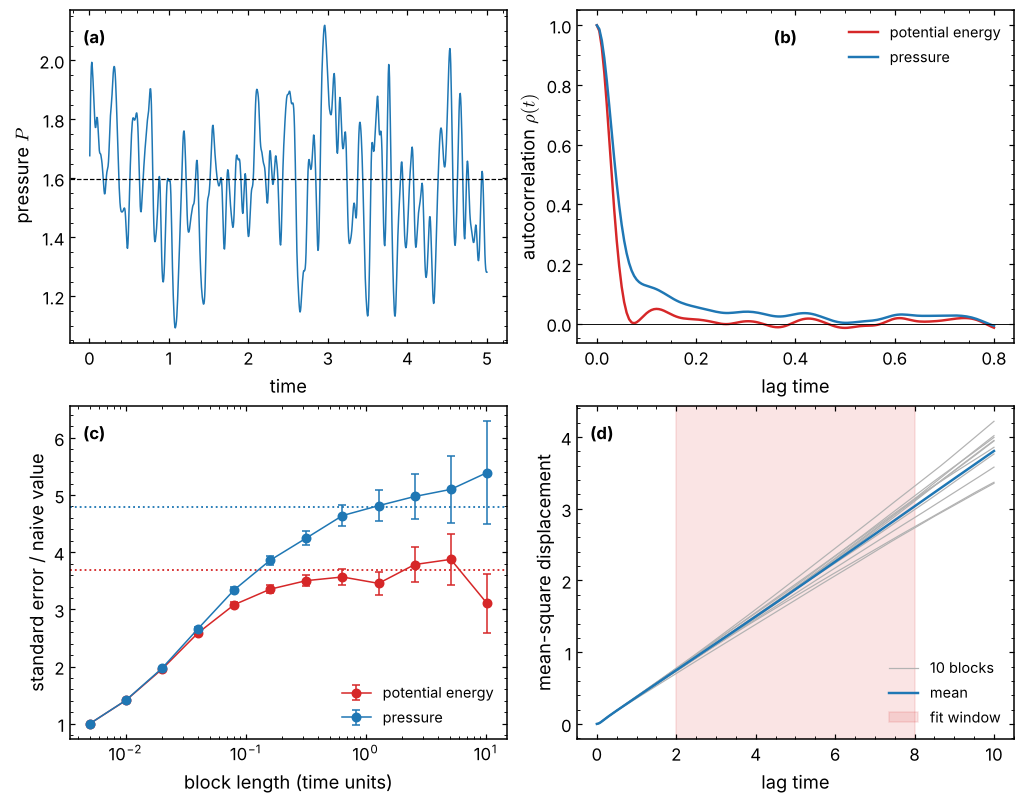

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.2))

ax = axes[0, 0]
n_show = 1000
ax.plot(time[:n_show], P[:n_show], "C0", lw=1)
ax.axhline(P.mean(), color="k", lw=0.8, ls="--")
ax.set_xlabel("time"); ax.set_ylabel("pressure $P$")
ep.panel_label(ax, "(a)")

ax = axes[0, 1]
max_lag = 160
lag_t = np.arange(max_lag + 1) * dt
ax.plot(lag_t, ep.autocorrelation(U, max_lag), "C3", label="potential energy")
ax.plot(lag_t, ep.autocorrelation(P, max_lag), "C0", label="pressure")
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("lag time"); ax.set_ylabel(r"autocorrelation $\rho(t)$")
ax.legend(); ep.panel_label(ax, "(b)", x=0.45)

ax = axes[1, 0]
for name, c in (("U/N", "C3"), ("P", "C0")):
    x = series[name]
    sizes, sem_b, err_b = ep.blocking_curve(x, min_blocks=16)
    naive = ep.mean_sem(x)[2]
    ax.errorbar(sizes * dt, sem_b / naive, yerr=err_b / naive, fmt="o-", color=c, lw=1,
                label={"U/N": "potential energy", "P": "pressure"}[name])
    ax.axhline(np.sqrt(2 * tau[name]), color=c, ls=":", lw=1.2)
ax.set_xscale("log")
ax.set_xlabel("block length (time units)"); ax.set_ylabel("standard error / naive value")
ax.legend(loc="lower right"); ep.panel_label(ax, "(c)")

msd_data = np.loadtxt(data_dir / "lj_md_msd_blocks.csv", delimiter=",", skiprows=1)
lag, msd = msd_data[:, 0], msd_data[:, 1:]
ax = axes[1, 1]
ax.plot(lag, msd, color="0.7", lw=0.8)
ax.plot([], [], color="0.7", lw=0.8, label="10 blocks")
ax.plot(lag, msd.mean(axis=1), "C0", label="mean")
ax.axvspan(2, 8, color="C3", alpha=0.12, label="fit window")
ax.set_xlabel("lag time"); ax.set_ylabel("mean-square displacement")
ax.legend(loc="lower right"); ep.panel_label(ax, "(d)")
plt.show()

**Panel (c)** is the blocking analysis of Section 17.4, with the standard
error divided by its naive value. The dotted lines are the independent
estimates $\sqrt{2\tau_\text{int}}$ from the autocorrelation functions.

The energy curve levels off for blocks longer than about half a time unit,
at the value given by $\tau_\text{int}$. The pressure curve is less tidy,
as real data often are: it flattens near the $\tau_\text{int}$ value but
continues to creep upwards, within its growing error bars. The cause is
visible in panel (b). The pressure autocorrelation function has a small
positive tail that persists for several tenths of a time unit, and the
summation window of the $\tau_\text{int}$ estimate cuts part of it off.
The last points of a blocking curve, with few blocks, carry large error
bars and should not be over-read, but the trend is a reason to prefer
long blocks here.

We take blocks of 500 steps (2.5 time units, 80 blocks), which leaves
enough blocks for a reliable standard deviation.

In [6]:
block = 500
results = {}
print(f"blocks of {block} steps ({block * dt} time units), {time.size // block} blocks\n")
print("quantity   naive          from tau_int    block average    result")
for name, x in series.items():
    naive = ep.mean_sem(x)[2]
    u_tau = ep.sem_correlated(x)
    bm = ep.block_means(x, block)
    u_block = bm.std(ddof=1) / np.sqrt(bm.size)
    results[name] = (x.mean(), u_block)
    print(f"{name:<8}   {naive:.5f}        {u_tau:.5f}         {u_block:.5f}        {ep.format_result(x.mean(), u_block)}")

blocks of 500 steps (2.5 time units), 80 blocks

quantity   naive          from tau_int    block average    result
T          0.00015        0.00057         0.00056        0.98361 ± 0.00056
U/N        0.00023        0.00085         0.00084        -4.70460 ± 0.00084
P          0.00101        0.00486         0.00471        1.5970 ± 0.0047


The two corrected estimates agree with each other to within their own
precision (with 80 blocks, the block estimate is itself uncertain by about
8 %, Section 4.3). For the pressure, panel (c) suggests that the true
standard error may be some 10 % larger than the value in the table. An
uncertainty known to 10 or 20 % is a perfectly good uncertainty; this is
why two significant figures are the most that an error bar deserves.

## Step 4. Are the error bars believable?

In the notebooks with synthetic data we verified error bars by repeating
the experiment thousands of times. With a real simulation the equivalent
is to run independent replicas, which is the best test and is left as an
exercise. A cheaper check uses the run itself: the two halves of the run
are (nearly) independent measurements of the same quantity, so their
difference should be compatible with zero in units of its uncertainty
(Section 1.6).

In [7]:
half = time.size // 2
print("quantity   first half    second half    difference / its uncertainty")
for name, x in series.items():
    a, b = x[:half], x[half:]
    ua = ep.block_means(a, block).std(ddof=1) / np.sqrt(half // block)
    ub = ep.block_means(b, block).std(ddof=1) / np.sqrt(half // block)
    z = (a.mean() - b.mean()) / np.hypot(ua, ub)
    z_naive = (a.mean() - b.mean()) / np.hypot(ep.mean_sem(a)[2], ep.mean_sem(b)[2])
    print(f"{name:<8}  {a.mean():10.5f}   {b.mean():10.5f}       {z:+.2f}    (with naive error bars: {z_naive:+.2f})")

quantity   first half    second half    difference / its uncertainty
T            0.98398      0.98323       +0.66    (with naive error bars: +2.43)
U/N         -4.70520     -4.70400       -0.72    (with naive error bars: -2.63)
P            1.59539      1.59861       -0.34    (with naive error bars: -1.59)


With the block error bars the two halves agree to within one standard
uncertainty for all three quantities: no sign of drift, and no sign that
the error bars are too small. With the naive error bars the same
differences would have been read as 2.4 and 2.6 standard uncertainties for
temperature and energy, and one might have concluded, wrongly, that the
system was still equilibrating.

### Saving less often loses almost nothing

Since neighbouring samples are nearly redundant, most of them can be
discarded without harm. The table shows the block-average standard error of
the pressure when only every $n$th step is kept.

In [8]:
print("keep every   samples   naive s/sqrt(N)   correct standard error")
for n in (1, 5, 20, 50, 100):
    x = P[::n]
    u_corr = ep.block_means(x, max(block // n, 1)).std(ddof=1) / np.sqrt(x.size // max(block // n, 1))
    print(f"   {n:4d}      {x.size:6d}      {ep.mean_sem(x)[2]:.5f}           {u_corr:.5f}")

keep every   samples   naive s/sqrt(N)   correct standard error
      1       40000      0.00101           0.00471
      5        8000      0.00227           0.00471
     20        2000      0.00454           0.00521
     50         800      0.00718           0.00735
    100         400      0.01015           0.01017


Keeping every 5th step loses nothing. Keeping every 20th step, an
interval of about $2\tau_\text{int}$, reduces the data twentyfold and
increases the true uncertainty by only 10 %. Beyond that, information is
being lost, the samples are effectively independent, and the naive error
bar becomes correct. Saving every step buys nothing except disk usage and
a false sense of precision.

## Step 5. The self-diffusion coefficient

The diffusion coefficient follows from the long-time slope of the
mean-square displacement (Einstein relation),

$$ \langle |\boldsymbol r(t) - \boldsymbol r(0)|^2\rangle \to 6Dt + \text{const} . $$

$D$ is not an average of a time series, so the methods above do not apply
directly. The cleanest route to its uncertainty is the one recommended in
Section 17.5 for derived quantities: divide the run into blocks long
compared with the correlation time, compute the complete quantity in each
block, and use the scatter between blocks. The script saved the
mean-square displacement separately for 10 consecutive blocks of 20 time
units (panel (d)). For each block we fit a straight line between lag times
2 and 8 and take $D = \text{slope}/6$.

In [9]:
def diffusion(lag, msd, t_min, t_max):
    sel = (lag >= t_min) & (lag <= t_max)
    return np.array([np.polyfit(lag[sel], msd[sel, b], 1)[0] / 6 for b in range(msd.shape[1])])

D_blocks = diffusion(lag, msd, 2, 8)
D, s_D, u_D = ep.mean_sem(D_blocks)
print("D in each block:", np.round(D_blocks, 4))
print("D =", ep.format_result(D, u_D), f"  (relative uncertainty {u_D / D:.1%}, from {D_blocks.size} blocks)")

D in each block: [0.0668 0.0665 0.0659 0.0594 0.0564 0.0707 0.066  0.0618 0.0658 0.0555]
D = 0.0635 ± 0.0016   (relative uncertainty 2.5%, from 10 blocks)


With only ten blocks, the standard error is itself uncertain by about a
quarter, and a 95 % interval should use Student's $t$ ($t = 2.26$ for nine
degrees of freedom) and not the factor 2.

**The fit window is a choice**, and choices are a source of systematic
uncertainty. A simple test is to vary it.

In [10]:
print("fit window     D          u_D")
for t_min, t_max in ((1, 5), (2, 8), (4, 10), (6, 10)):
    Db = diffusion(lag, msd, t_min, t_max)
    print(f"  {t_min:2d} to {t_max:2d}    {Db.mean():.4f}     {Db.std(ddof=1) / np.sqrt(Db.size):.4f}")

fit window     D          u_D
   1 to  5    0.0625     0.0010
   2 to  8    0.0635     0.0016
   4 to 10    0.0643     0.0021
   6 to 10    0.0645     0.0024


The estimate rises by about 3 % from the earliest to the latest window,
an amount comparable with the statistical uncertainty. (The four values
come from the same trajectories, so they are strongly correlated and their
differences are more significant than the individual error bars suggest.)
A slow approach of the mean-square displacement to its asymptotic slope
would produce such a trend. Windows at long lag times also give noisier
estimates, because fewer independent time origins contribute. We keep the
window from 2 to 8 and note that the choice of window contributes an
uncertainty of 1 to 2 %, to be added to the statistical one.

## Step 6. What the error bars do not include

The final statistical results of this run are:

In [11]:
print("T   =", ep.format_result(*results["T"]))
print("U/N =", ep.format_result(*results["U/N"]))
print("P   =", ep.format_result(*results["P"]))
print("D   =", ep.format_result(D, u_D))

T   = 0.98361 ± 0.00056
U/N = -4.70460 ± 0.00084
P   = 1.5970 ± 0.0047
D   = 0.0635 ± 0.0016


These uncertainties answer one question: how much would the averages
change if the same simulation were run again with different initial
velocities? They say nothing about the following.

**The state point.** The run is at constant energy, and the temperature is
an *output*: $T = 0.984$, not the 1.0 that was aimed for during
equilibration. Reporting the pressure above as "the pressure at
$\rho = 0.8$, $T = 1.0$" would be an error far larger than the statistical
uncertainty, because $(\partial P/\partial T)_\rho$ is large in a dense
liquid (roughly 4 to 5 in reduced units near this state point; it can be
measured with a second run at a slightly different energy). A temperature
offset of 0.016 then shifts the pressure by about 0.07, more than ten
times $u_P$. This is the same lesson as the temperature of the glycerol in
[Chapter 21](21_falling_sphere_viscosity.ipynb): define the measurand before
quoting its uncertainty.

**The model.** The potential is truncated and shifted at $2.5\,\sigma$. The
results are properties of that model. They differ substantially from those
of the full Lennard-Jones potential (the pressure by several tenths of a
reduced unit at this density) and must not be compared with them without
correction.

**Finite size.** With 256 particles in a periodic box, thermodynamic
averages carry errors of order $1/N$. The diffusion coefficient is
affected much more strongly, because the hydrodynamic flow field of a
moving particle interacts with its periodic images. The correction derived
by Yeh and Hummer,

$$ D_\infty = D_\text{PBC} + \frac{\xi\,k_\mathrm{B}T}{6\pi\eta L} , \qquad \xi \approx 2.837 , $$

with $\eta$ the shear viscosity and $L$ the box length, decays only as
$1/L$ and is typically of order ten per cent or more for a few hundred
particles, several times the statistical uncertainty found above.

**The time step.** Velocity-Verlet averages carry a discretisation error
of order $\Delta t^2$. It is checked by repeating the run with half the
time step.

**Unsampled slow processes.** A simple liquid at this state point relaxes
in about a time unit, and 200 time units are ample. For a glass-former, a
polymer melt or a system near a phase transition the same run length could
be shorter than one correlation time, and every error bar computed from it
would be meaningless (Section 17.6).

A complete statement of a simulation result therefore reads like the
uncertainty budget of an experiment: the statistical uncertainty from
block averaging, plus an estimate or bound for each systematic effect,
obtained by varying the system size, the time step and the cutoff.

## Summary

* Successive MD configurations are correlated. Here the naive standard
  error was too small by factors of 3.7 to 4.8; in slowly relaxing systems
  the factor can be in the hundreds.
* Block averaging and the integrated autocorrelation time give consistent,
  correct error bars; use one and check with the other.
* Split-run comparisons and independent replicas test the error bars.
* For derived quantities such as $D$, compute the whole quantity in
  independent blocks.
* The statistical error bar is the smallest part of the story. State
  point, model, system size and time step each need their own estimate.

## References

* M. P. Allen and D. J. Tildesley, *Computer Simulation of Liquids*, 2nd ed.
  (Oxford University Press, 2017).
* D. Frenkel and B. Smit, *Understanding Molecular Simulation*, 2nd ed.
  (Academic Press, 2002).
* I.-C. Yeh and G. Hummer, "System-size dependence of diffusion coefficients
  and viscosities from molecular dynamics simulations with periodic boundary
  conditions", *J. Phys. Chem. B* **108**, 15873 (2004).

## Exercises

1. Run `scripts/run_lj_md.py` five times with different seeds (change
   `SEED`). Is the scatter of the five mean pressures consistent with the
   error bar found here?
2. Repeat the run with `DT = 0.0025` and twice the number of steps. Do
   $U/N$ and $P$ change by more than their statistical uncertainty?
3. Repeat with `N_CELLS = 5` (500 particles). By how much does $D$ change?
   Estimate the viscosity that the Yeh–Hummer formula would imply.
4. Estimate the constant-volume heat capacity from the fluctuations of the
   kinetic energy in the NVE ensemble (Lebowitz–Percus–Verlet formula) and
   obtain its uncertainty with `ep.jackknife` over blocks.
5. Equilibrate badly on purpose (set `N_EQUIL = 200`, `N_RELAX = 0`) and
   repeat the split-half test.

---

**Previous:** [22. Chemistry: activation energy from an Arrhenius plot](22_arrhenius_activation_energy.ipynb) &nbsp;·&nbsp; **Next:** [24. Nuclear physics: a half-life from decay counts](24_radioactive_decay_counts.ipynb)